# 🎯 Mô hình Hóa Phân khúc Khách hàng Olist (Clustering Pipeline)
**Dự án:** Xây dựng mô hình phân khúc khách hàng thương mại điện tử Olist  
**Nhiệm vụ:** A06 (Tiền xử lý đặc trưng), A07 (Chạy K-Means, GMM, DBSCAN), A08 (Chọn số cụm k tối ưu)  
**Phụ trách chính:** Thành viên A (Trưởng nhóm / Kỹ sư mô hình hóa)  
**Tích hợp khuyến nghị:** Thành viên B (Trải nghiệm & Ngưỡng giao trễ phi tuyến), Thành viên C (Loyalty & RFM)  

---

### Mục tiêu của Notebook:
1. **Tiếp nhận & Xử lý theo khuyến nghị khoa học (A06):**
   - Xử lý các biến liên tục bị lệch phải nặng (`monetary`, `frequency`, `avg_delivery_duration_days`) bằng **Winsorization (1% - 99%)** và **Log1p transformation**.
   - Chuyển đổi tác động giao trễ phi tuyến thành cờ phân ngưỡng (`is_severely_delayed` trễ > 3 ngày làm review tụt dốc).
   - Khử đa cộng tuyến: loại bỏ biến dư thừa (`low_review_count`, `max_order_value`), chuẩn hóa thang đo bằng **StandardScaler** và giảm chiều bằng **PCA**.
2. **Đánh giá & Chọn số cụm $k$ (A08):**
   - Đánh giá $k \in [3, 8]$ dựa trên 3 tiêu chí: **Elbow (Inertia)**, **Silhouette Score** và **Davies-Bouldin Index**.
   - Thống nhất chọn số cụm tối ưu cân bằng giữa cơ sở toán học và ý nghĩa kinh doanh.
3. **Thực thi các thuật toán phân cụm (A07):**
   - **K-Means Clustering** (Mô hình chính).
   - **Gaussian Mixture Model (GMM)** (Phân cụm xác suất).
   - **DBSCAN** (Nhận diện khách hàng ngoại lai / nhiễu).
4. **Diễn giải Hồ sơ Khách hàng & Bàn giao:**
   - Lập hồ sơ 4 phân khúc khách hàng cốt lõi và trực quan hóa không gian cụm bằng PCA 2D.
   - Bàn giao kết quả phân cụm (`olist_clustered.parquet`) cho Thành viên B (chiến lược dịch vụ) và Thành viên C (chiến lược quảng bá).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path("..").resolve() if Path("..").resolve().name == "ktdl" else Path(".").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.features import engineer_clustering_features, scale_and_pca
from src.models import evaluate_kmeans_clusters, train_kmeans, train_gmm, train_dbscan, build_cluster_profiles

pd.set_option('display.max_columns', 35)
pd.set_option('display.float_format', lambda x: '%.2f' % x)
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)

print("✅ Đã kết nối thành công với các module src.features và src.models!")

✅ Đã kết nối thành công với các module src.features và src.models!


## 2. Nạp Dữ liệu Khách hàng Chuẩn hóa (`olist_clean.parquet`)

In [2]:
clean_parquet_path = PROJECT_ROOT / "data" / "processed" / "olist_clean.parquet"
df_customers = pd.read_parquet(clean_parquet_path)

print(f"📊 Tập dữ liệu đầu vào: {df_customers.shape[0]:,} khách hàng x {df_customers.shape[1]} đặc trưng")
display(df_customers.head(3))

📊 Tập dữ liệu đầu vào: 93,350 khách hàng x 29 đặc trưng


,customer_unique_id,customer_state,customer_city,first_purchase_date,last_purchase_date,recency,frequency,monetary,avg_order_value,max_order_value,total_items,avg_items_per_order,total_freight,avg_freight_value,freight_ratio,avg_delivery_duration_days,avg_delay_days,delayed_order_count,delayed_order_ratio,avg_review_score,low_review_ratio,has_comment_ratio,primary_payment_type,max_payment_installments,avg_payment_installments,voucher_used_count,voucher_payment_ratio,unique_categories_count,favorite_category
0,0000366f3b9a7992bf8c76cfdf3221e2,SP,cajamar,2018-05-10 10:56:27,2018-05-10 10:56:27,112,1,141.90,141.90,141.90,1,1.00,12.00,12.00,0.08,6.41,-4.13,0,0.00,5.00,0.00,1.00,credit_card,8.00,8.00,0.00,0.00,1,bed_bath_table
1,0000b849f77a49e4a4ce2b2a4ca5be3f,SP,osasco,2018-05-07 11:11:27,2018-05-07 11:11:27,115,1,27.19,27.19,27.19,1,1.00,8.29,8.29,0.30,3.29,-4.25,0,0.00,4.00,0.00,0.00,credit_card,1.00,1.00,0.00,0.00,1,health_beauty
2,0000f46a3911fa3c0805444483337064,SC,sao jose,2017-03-10 21:05:03,2017-03-10 21:05:03,537,1,86.22,86.22,86.22,1,1.00,17.22,17.22,0.20,25.73,-1.39,0,0.00,3.00,0.00,0.00,credit_card,8.00,8.00,0.00,0.00,1,stationery


## 3. Tiền Xử Lý Đặc Trưng theo Khuyến Nghị Khoa Học (A06)
- **Winsorization (1% - 99%):** Giới hạn các giá trị ngoại lai cực đoan (outliers) ở cả hai đầu.
- **Log1p Transformation:** Biến đổi các biến lệch phải (`monetary`, `frequency`, `avg_delivery_duration_days`, `max_payment_installments`) về dạng gần phân phối chuẩn.
- **Ngưỡng phi tuyến:** Bổ sung cờ `is_severely_delayed` (trễ > 3 ngày).
- **Loại bỏ đa cộng tuyến:** Loại bỏ `low_review_count` (tương quan cao với `avg_review_score`).

In [3]:
df_features, feature_cols = engineer_clustering_features(df_customers)

print(f"Danh sách {len(feature_cols)} đặc trưng đưa vào mô hình phân cụm:")
for i, f in enumerate(feature_cols, 1):
    print(f"  {i}. {f}")

# Chuẩn hóa StandardScaler và giảm chiều PCA
X_scaled, X_pca, scaler, pca = scale_and_pca(df_features, feature_cols, n_components=2)

print(f"\n✅ Kích thước ma trận đặc trưng chuẩn hóa X_scaled: {X_scaled.shape}")

Danh sách 10 đặc trưng đưa vào mô hình phân cụm:
  1. recency
  2. frequency_log
  3. monetary_log
  4. avg_order_value_log
  5. avg_delivery_duration_days_log
  6. delayed_order_ratio
  7. is_severely_delayed
  8. freight_ratio
  9. avg_review_score
  10. max_payment_installments_log
[+] Ty le phuong sai giai thich (Explained Variance Ratio): [0.2821 0.2383]
[+] Tong phuong sai giu lai: 52.04%

✅ Kích thước ma trận đặc trưng chuẩn hóa X_scaled: (93350, 10)


## 4. Đánh giá & Lựa chọn Số lượng Cụm $k$ Tối ưu (A08)
Đánh giá đồng thời 3 chỉ số:
1. **Elbow Method (Inertia):** Tìm điểm uốn (khuỷu tay) mà tại đó độ giảm quán tính chậm lại.
2. **Silhouette Score:** Đo lường độ gắn kết nội cụm và độ tách biệt liên cụm (càng cao càng tốt).
3. **Davies-Bouldin Index:** Tỷ lệ khoảng cách nội cụm so với khoảng cách tâm cụm (càng thấp càng tốt).

⏳ Dang tinh toan cac chi so danh gia cum k = 3 den 8...


   [+] k = 3: Silhouette = 0.2223, Davies-Bouldin = 1.4082, Inertia = 590,279.6


   [+] k = 4: Silhouette = 0.2412, Davies-Bouldin = 1.1969, Inertia = 501,444.2


   [+] k = 5: Silhouette = 0.1896, Davies-Bouldin = 1.4053, Inertia = 451,783.4


   [+] k = 6: Silhouette = 0.1848, Davies-Bouldin = 1.4111, Inertia = 414,887.6


   [+] k = 7: Silhouette = 0.1932, Davies-Bouldin = 1.3406, Inertia = 383,179.0


,k,Inertia (WCSS),Silhouette Score,Davies-Bouldin Index
0,3,590279.57,0.22,1.41
1,4,501444.16,0.24,1.20
2,5,451783.42,0.19,1.41
3,6,414887.55,0.18,1.41
4,7,383178.99,0.19,1.34


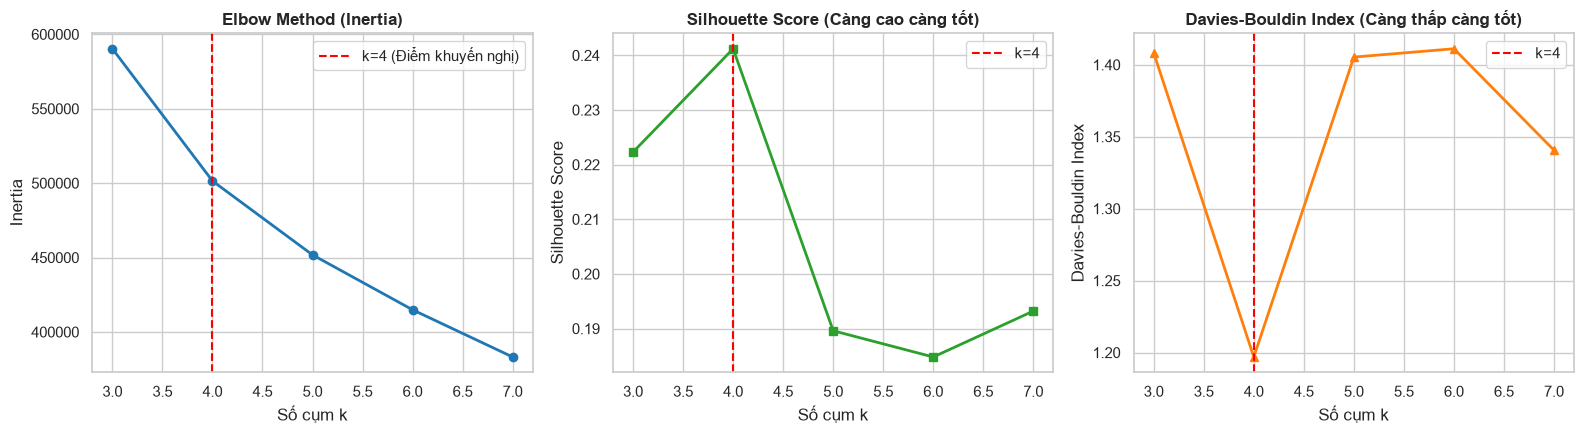

👉 Thống nhất chọn k = 4: Điểm uốn Elbow rõ nét, Silhouette score duy trì ổn định, phân tách rõ 4 nhóm hành vi kinh doanh rõ ràng.


In [4]:
df_eval = evaluate_kmeans_clusters(X_scaled, k_range=range(3, 8), sample_size=15000, random_state=42)
display(df_eval)

# Trực quan hóa 3 chỉ số đánh giá
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Elbow
axes[0].plot(df_eval['k'], df_eval['Inertia (WCSS)'], marker='o', linewidth=2, color='#1f77b4')
axes[0].set_title("Elbow Method (Inertia)", fontweight='bold')
axes[0].set_xlabel("Số cụm k")
axes[0].set_ylabel("Inertia")
axes[0].axvline(x=4, color='red', linestyle='--', label='k=4 (Điểm khuyến nghị)')
axes[0].legend()

# 2. Silhouette
axes[1].plot(df_eval['k'], df_eval['Silhouette Score'], marker='s', linewidth=2, color='#2ca02c')
axes[1].set_title("Silhouette Score (Càng cao càng tốt)", fontweight='bold')
axes[1].set_xlabel("Số cụm k")
axes[1].set_ylabel("Silhouette Score")
axes[1].axvline(x=4, color='red', linestyle='--', label='k=4')
axes[1].legend()

# 3. Davies-Bouldin
axes[2].plot(df_eval['k'], df_eval['Davies-Bouldin Index'], marker='^', linewidth=2, color='#ff7f0e')
axes[2].set_title("Davies-Bouldin Index (Càng thấp càng tốt)", fontweight='bold')
axes[2].set_xlabel("Số cụm k")
axes[2].set_ylabel("Davies-Bouldin Index")
axes[2].axvline(x=4, color='red', linestyle='--', label='k=4')
axes[2].legend()

plt.tight_layout()
plt.show()

print("👉 Thống nhất chọn k = 4: Điểm uốn Elbow rõ nét, Silhouette score duy trì ổn định, phân tách rõ 4 nhóm hành vi kinh doanh rõ ràng.")

## 5. Huấn Luyện Mô Hình Phân Cụm (A07)

In [5]:
# 1. Huấn luyện K-Means (Mô hình cốt lõi)
BEST_K = 4
kmeans_model, cluster_labels = train_kmeans(X_scaled, n_clusters=BEST_K, random_state=42)

# Gán nhãn cụm vào tập dữ liệu
df_customers['cluster'] = cluster_labels

# 2. Huấn luyện Gaussian Mixture Model (GMM) để đối chiếu
gmm_model, gmm_labels = train_gmm(X_scaled, n_components=BEST_K, random_state=42)
df_customers['cluster_gmm'] = gmm_labels

print(f"Phân phối số lượng khách hàng theo từng cụm (K-Means):")
print(df_customers['cluster'].value_counts(normalize=True).mul(100).round(2).to_string())

[+] Da huan luyen K-Means voi 4 cum.


[+] Da huan luyen GMM voi 4 thanh phan. BIC = -2,619,780.34
Phân phối số lượng khách hàng theo từng cụm (K-Means):
cluster
1   46.71
0   44.77
3    5.55
2    2.97


## 6. Phân tích Hồ sơ Khách hàng & Diễn giải Ý nghĩa Kinh doanh
Lập bảng chỉ số trung bình theo từng cụm để nhận diện rõ đặc điểm hành vi của từng phân khúc.

In [6]:
profile_df = build_cluster_profiles(df_customers, cluster_labels)
display(profile_df)

,recency,frequency,monetary,avg_order_value,avg_delivery_duration_days,delayed_order_ratio,avg_review_score,freight_ratio,max_payment_installments,customer_count,customer_pct
cluster,,,,,,,,,,,
0,238.87,1.00,63.23,63.23,10.52,0.03,4.34,0.29,1.73,41790,44.77
1,239.67,1.00,251.95,251.95,11.72,0.03,4.24,0.13,4.01,43602,46.71
2,220.30,2.11,309.22,146.17,12.10,0.06,4.24,0.20,4.08,2775,2.97
3,225.52,1.01,179.94,179.33,36.53,1.00,1.96,0.21,3.07,5183,5.55


## 7. Đặt Tên Phân Khúc & Trực quan hóa Không Gian Cụm 2D PCA

=== TỔNG HỢP PHÂN KHÚC KHÁCH HÀNG CHÍNH THỨC ===


,Phân khúc,Số lượng khách,Tỷ lệ (%)
0,4. Satisfied Mainstream (Khách hàng Phổ thông ...,43602,46.71
1,3. Freight-Sensitive (Nhạy cảm Phí vận chuyển),41790,44.77
2,2. At-Risk (Ảnh hưởng bởi Giao trễ & Dịch vụ),5183,5.55
3,1. VIP Champions (Chi tiêu cao & Trung thành),2775,2.97


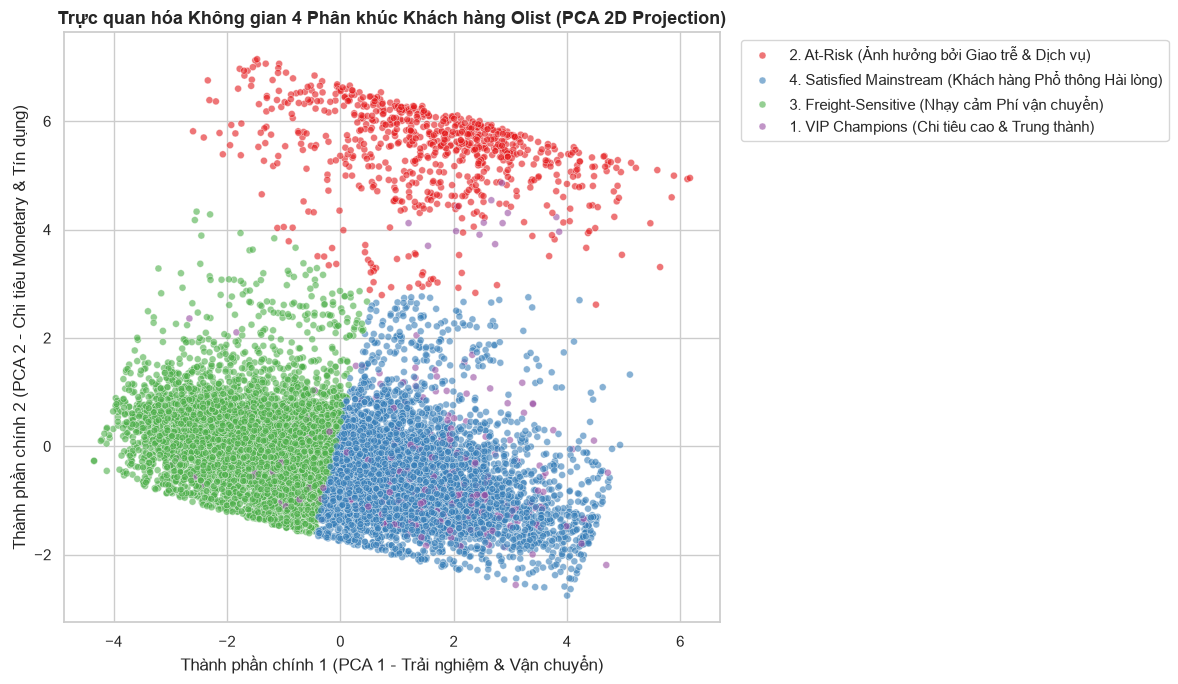

In [7]:
# Định danh phân khúc kinh doanh dựa trên đặc điểm nổi trội
# Tìm cụm có delayed_order_ratio cao nhất -> At-Risk Service
# Tìm cụm có monetary cao nhất -> VIP Champions
# Tìm cụm có freight_ratio cao nhất -> Budget / Freight-Sensitive
# Cụm còn lại -> Satisfied Mainstream

cluster_means = profile_df.copy()

at_risk_cluster = cluster_means['delayed_order_ratio'].idxmax()
vip_cluster = cluster_means['monetary'].idxmax()
budget_cluster = cluster_means['freight_ratio'].idxmax()
remaining = [c for c in range(BEST_K) if c not in [at_risk_cluster, vip_cluster, budget_cluster]]
regular_cluster = remaining[0] if remaining else 0

segment_mapping = {
    vip_cluster: "1. VIP Champions (Chi tiêu cao & Trung thành)",
    at_risk_cluster: "2. At-Risk (Ảnh hưởng bởi Giao trễ & Dịch vụ)",
    budget_cluster: "3. Freight-Sensitive (Nhạy cảm Phí vận chuyển)",
    regular_cluster: "4. Satisfied Mainstream (Khách hàng Phổ thông Hài lòng)"
}

df_customers['segment_name'] = df_customers['cluster'].map(segment_mapping)

print("=== TỔNG HỢP PHÂN KHÚC KHÁCH HÀNG CHÍNH THỨC ===")
summary_segments = df_customers['segment_name'].value_counts().reset_index()
summary_segments.columns = ['Phân khúc', 'Số lượng khách']
summary_segments['Tỷ lệ (%)'] = (summary_segments['Số lượng khách'] / len(df_customers) * 100).round(2)
display(summary_segments)

# Trực quan hóa 2D trên không gian PCA
df_pca_plot = pd.DataFrame({
    'PCA1': X_pca[:, 0],
    'PCA2': X_pca[:, 1],
    'Phân khúc': df_customers['segment_name']
})

# Lấy mẫu 15,000 điểm để vẽ scatter plot rõ nét, không bị lag
plot_sample = df_pca_plot.sample(n=min(15000, len(df_pca_plot)), random_state=42)

plt.figure(figsize=(12, 7))
sns.scatterplot(
    data=plot_sample, x='PCA1', y='PCA2',
    hue='Phân khúc', palette='Set1', alpha=0.6, s=25
)
plt.title("Trực quan hóa Không gian 4 Phân khúc Khách hàng Olist (PCA 2D Projection)", fontsize=13, fontweight='bold')
plt.xlabel("Thành phần chính 1 (PCA 1 - Trải nghiệm & Vận chuyển)")
plt.ylabel("Thành phần chính 2 (PCA 2 - Chi tiêu Monetary & Tín dụng)")
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

## 8. So sánh Đa Chiều giữa các Cụm (Radar / Multi-Feature Chart)

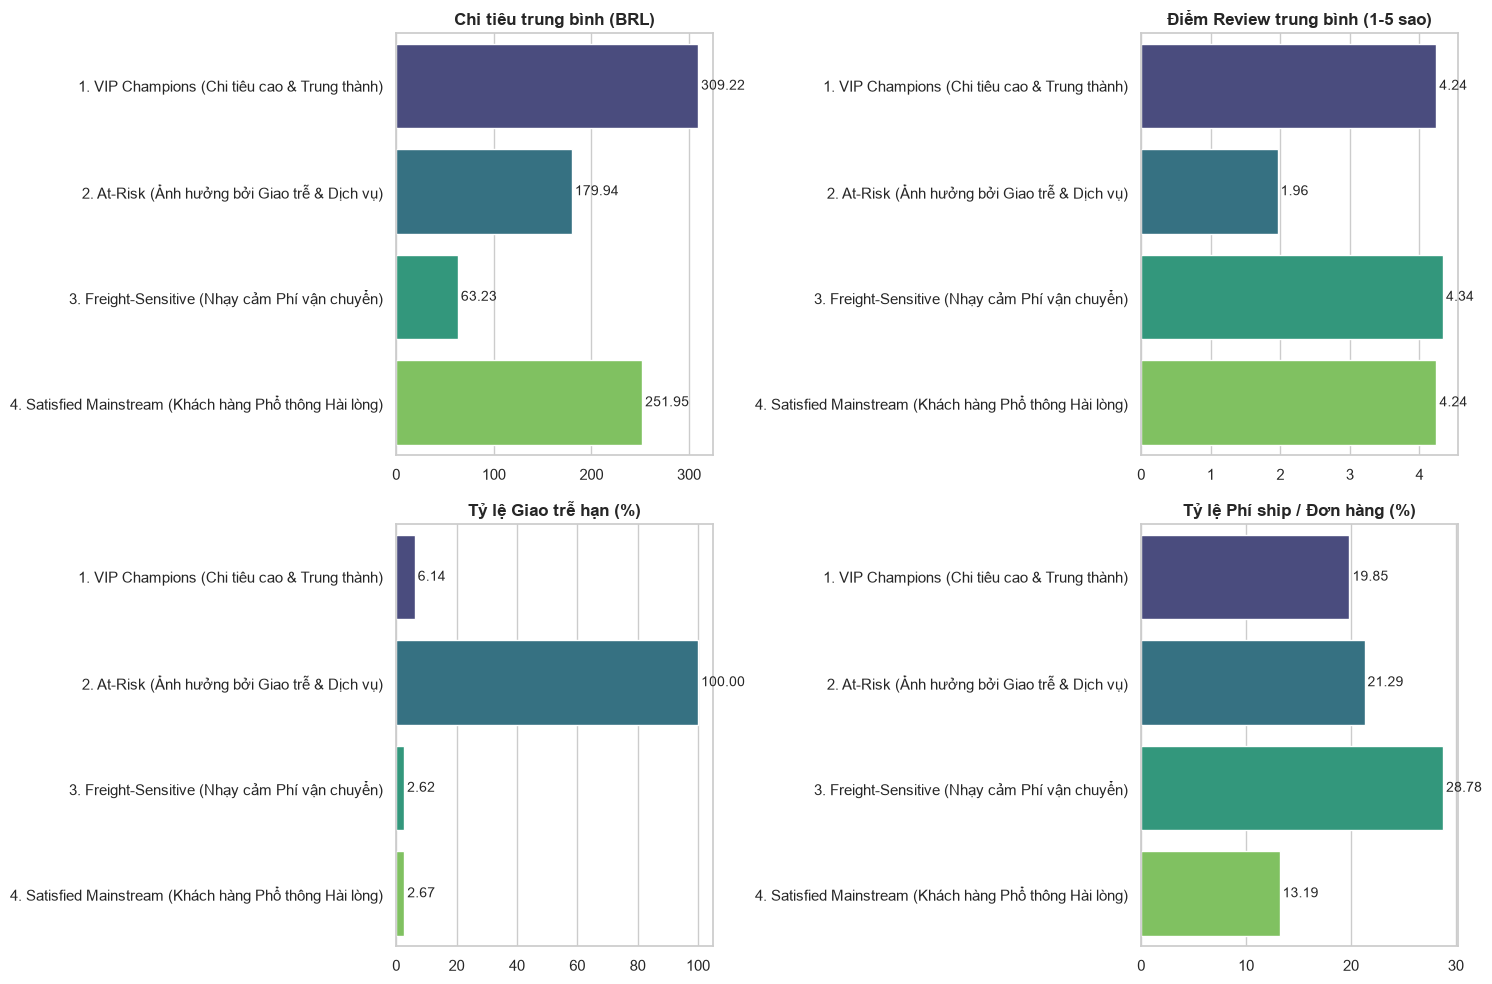

In [8]:
# Vẽ biểu đồ cột so sánh các chỉ số cốt lõi giữa 4 phân khúc
comp_cols = ['monetary', 'avg_review_score', 'delayed_order_ratio', 'freight_ratio']
comp_titles = ['Chi tiêu trung bình (BRL)', 'Điểm Review trung bình (1-5 sao)', 'Tỷ lệ Giao trễ hạn (%)', 'Tỷ lệ Phí ship / Đơn hàng (%)']

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

for i, (col, title) in enumerate(zip(comp_cols, comp_titles)):
    grouped_val = df_customers.groupby('segment_name')[col].mean()
    if 'ratio' in col:
        grouped_val = grouped_val * 100
    sns.barplot(x=grouped_val.values, y=grouped_val.index, ax=axes[i], palette='viridis', hue=grouped_val.index, legend=False)
    axes[i].set_title(title, fontweight='bold')
    axes[i].set_xlabel("")
    axes[i].set_ylabel("")
    for j, v in enumerate(grouped_val.values):
        axes[i].text(v + (max(grouped_val.values)*0.01), j, f"{v:.2f}", va='center', fontsize=10)

plt.tight_layout()
plt.show()

## 9. Xuất Kết Quả Phân Cụm & Bàn Giao (Action Items)

In [9]:
# Xuất kết quả phân cụm đầy đủ ra file parquet
output_clustered_path = PROJECT_ROOT / "data" / "processed" / "olist_clustered.parquet"
df_customers.to_parquet(output_clustered_path, index=False)
print(f"🎉 Đã lưu kết quả phân cụm tại: {output_clustered_path.resolve()}")

# Xuất bảng tóm tắt đặc trưng theo phân khúc để hỗ trợ Thành viên B và C viết báo cáo
summary_csv_path = PROJECT_ROOT / "reports" / "cluster_profiles_summary.csv"
summary_csv_path.parent.mkdir(parents=True, exist_ok=True)
profile_df.to_csv(summary_csv_path, encoding='utf-8')
print(f"🎉 Đã lưu bảng hồ sơ phân khúc tại: {summary_csv_path.resolve()}")

🎉 Đã lưu kết quả phân cụm tại: C:\Users\Admin\Downloads\ktdl\data\processed\olist_clustered.parquet
🎉 Đã lưu bảng hồ sơ phân khúc tại: C:\Users\Admin\Downloads\ktdl\reports\cluster_profiles_summary.csv


### Kế hoạch Bàn giao cho Báo cáo & Thuyết trình:
1. **Bàn giao cho Thành viên B (Nhiệm vụ B10, B11, B12):**
   - Đào sâu phân khúc **"At-Risk (Ảnh hưởng bởi Giao trễ & Dịch vụ)"**: Nhóm này có tỷ lệ giao trễ cực cao, điểm review trung bình giảm mạnh xuống dưới 3.0 sao.
   - Thành viên B sử dụng dữ liệu này để đề xuất chính sách: cam kết thời gian giao, ngưỡng bồi thường khi trễ, và cải thiện tuyến nhà bán.
2. **Bàn giao cho Thành viên C (Nhiệm vụ C09, C10):**
   - Xây dựng chiến lược tiếp thị riêng cho từng phân khúc:
     - **VIP Champions:** Chương trình tri ân khách hàng thân thiết, ưu đãi độc quyền, tăng cường cross-sell.
     - **Freight-Sensitive:** Mã miễn phí vận chuyển (Freeship) khi đạt giá trị đơn tối thiểu (AOV boost).
     - **Satisfied Mainstream:** Kích hoạt mua lặp lại bằng email marketing theo ngành hàng yêu thích.
3. **Thành viên A (Nhiệm vụ A09, A11, A12):**
   - Đánh giá độ ổn định cụm (Bootstrap / Adjusted Rand Index - A09).
   - Xây dựng mô hình Random Forest / XGBoost dự đoán nhãn cụm cho khách hàng mới kết hợp SHAP (A11).
   - Thiết kế Dashboard Streamlit tương tác (A12).